In [1]:
import time, re
import requests
from bs4 import BeautifulSoup
import pandas as pd

headers = {"User-Agent": "Mozilla/5.0", "Accept-Language": "en-US,en;q=0.9"}


import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')

In [ ]:
leagues = {
    "Bundesliga": "L1",
    "Premier League": "GB1",
    "LaLiga": "ES1",
    "Serie A": "IT1",
    "Ligue 1": "FR1",
    "Eredivisie": "NL1",
    "Liga Portugal": "PO1",
    "MLS": "MLS1",
    "Saudi Pro League": "SA1",
    "Brasileirão": "BRA1",
}


df=pd.DataFrame()

for league, league_id in leagues.items():
    for season in range(1930, 2027):
        url=f'https://www.transfermarkt.com/bundesliga/startseite/wettbewerb/{league_id}/plus/?saison_id={season}'
        html=requests.get(url, headers=headers).content
        
        table=[table for table in pd.read_html(html) if 'ø age' in table.columns][0]
        if len(table)==0:
            continue
        table.insert(0, 'League', league)
        table.insert(1, 'Season', season)

        df=pd.concat([df, table], ignore_index=True)

        print(f'{league} season {season}', end='\r')

In [ ]:
df.to_csv('team_age.csv', index=False)

In [2]:
df=pd.read_csv('team_age.csv')

In [3]:
df

,League,Season,Club,Club.1,name,Squad,ø age,Foreigners,ø market value,Total market value
0,Bundesliga,1930,NaN,Bayern Munich,23.0,27.4,12,€45.15m,€1.04bn,NaN
1,Bundesliga,1930,NaN,Borussia Dortmund,30.0,24.5,21,€19.60m,€587.90m,NaN
2,Bundesliga,1930,NaN,Bayer 04 Leverkusen,28.0,26.4,21,€18.59m,€520.45m,NaN
3,Bundesliga,1930,NaN,RB Leipzig,29.0,24.8,18,€17.76m,€514.95m,NaN
4,Bundesliga,1930,NaN,VfB Stuttgart,30.0,25.4,13,€13.32m,€399.45m,NaN
...,...,...,...,...,...,...,...,...,...,...
19313,Brasileirão,2026,NaN,Coritiba Foot Ball Club,33.0,28.2,6,€1.51m,€49.85m,NaN
19314,Brasileirão,2026,NaN,Mirassol Futebol Clube (SP),32.0,30.5,0,€955k,€30.58m,NaN
19315,Brasileirão,2026,NaN,Clube do Remo (PA),32.0,29.1,5,€718k,€22.98m,NaN
19316,Brasileirão,2026,NaN,Associação Chapecoense de Futebol,37.0,28.1,5,€597k,€22.10m,NaN


In [4]:
df.isna().mean()

League                0.000000
Season                0.000000
Club                  1.000000
Club.1                0.050212
name                  0.050212
Squad                 0.037064
ø age                 0.000000
Foreigners            0.000000
ø market value        0.000000
Total market value    0.949788
dtype: float64

In [5]:
df=df.drop(columns=['Club', 'Total market value', 'Foreigners', 'ø market value', 'Total market value'])

In [6]:
df=df.dropna(subset='Club.1')

In [7]:
df.columns=['league', 'season', 'club', 'squad', 'average_age', 'foreigners']

In [8]:
df=df.dropna(subset='average_age')

In [9]:
df['foreigners']=df['foreigners'].apply(pd.to_numeric)

In [10]:
df=df.drop_duplicates(subset=['club', 'squad', 'average_age'])
df=df[df['season']!=1930]

In [11]:
df

,league,season,club,squad,average_age,foreigners
627,Bundesliga,1963,1.FC Saarbrücken,18.0,25.0,0
628,Bundesliga,1963,1.FC Kaiserslautern,19.0,25.4,1
629,Bundesliga,1963,1.FC Köln,18.0,26.6,0
630,Bundesliga,1963,1.FC Nuremberg,24.0,26.0,0
631,Bundesliga,1963,Borussia Dortmund,19.0,27.1,0
...,...,...,...,...,...,...
19270,Brasileirão,2024,Sport Club do Recife,76.0,23.4,9
19271,Brasileirão,2024,Esporte Clube Vitória,69.0,24.0,6
19272,Brasileirão,2024,Ceará Sporting Club,48.0,25.7,5
19273,Brasileirão,2024,Esporte Clube Juventude,57.0,25.3,5


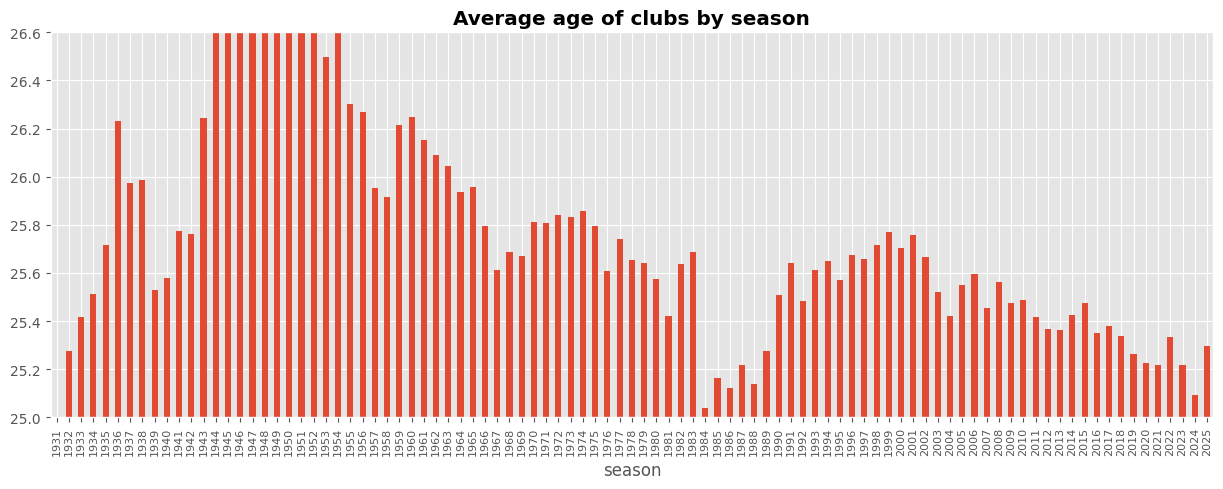

In [12]:
plt.figure(figsize=(15,5))
df.groupby('season')['average_age'].mean().plot.bar()
plt.title('Average age of clubs by season', fontweight='bold')
plt.ylim(25, 26.6)
plt.xticks(size=8)
plt.show()

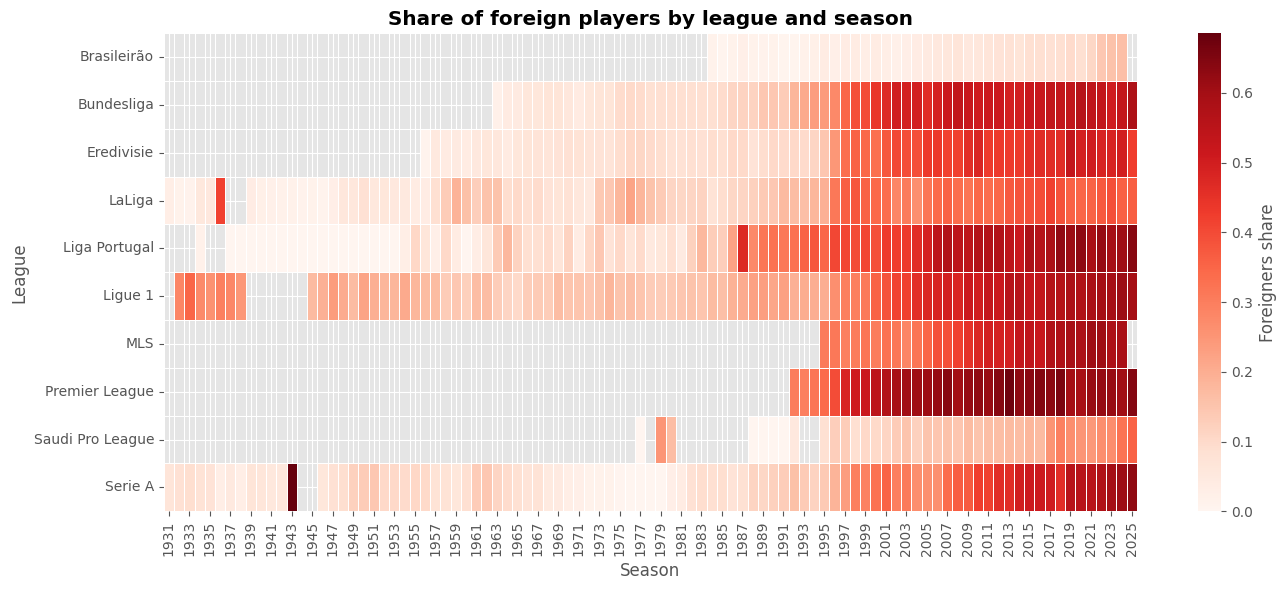

In [13]:
df['foreigners_%']=df['foreigners']/df['squad']

matrix=pd.pivot_table(data=df, index='league', columns='season', values='foreigners_%', aggfunc='mean')

plt.figure(figsize=(14, 6))
sns.heatmap(matrix, annot=False, fmt=".0%", cmap="Reds", linewidths=0.5,
            cbar_kws={"label": "Foreigners share"})
plt.xlabel("Season")
plt.ylabel("League")
plt.title("Share of foreign players by league and season", fontweight='bold')
plt.tight_layout()
plt.show()

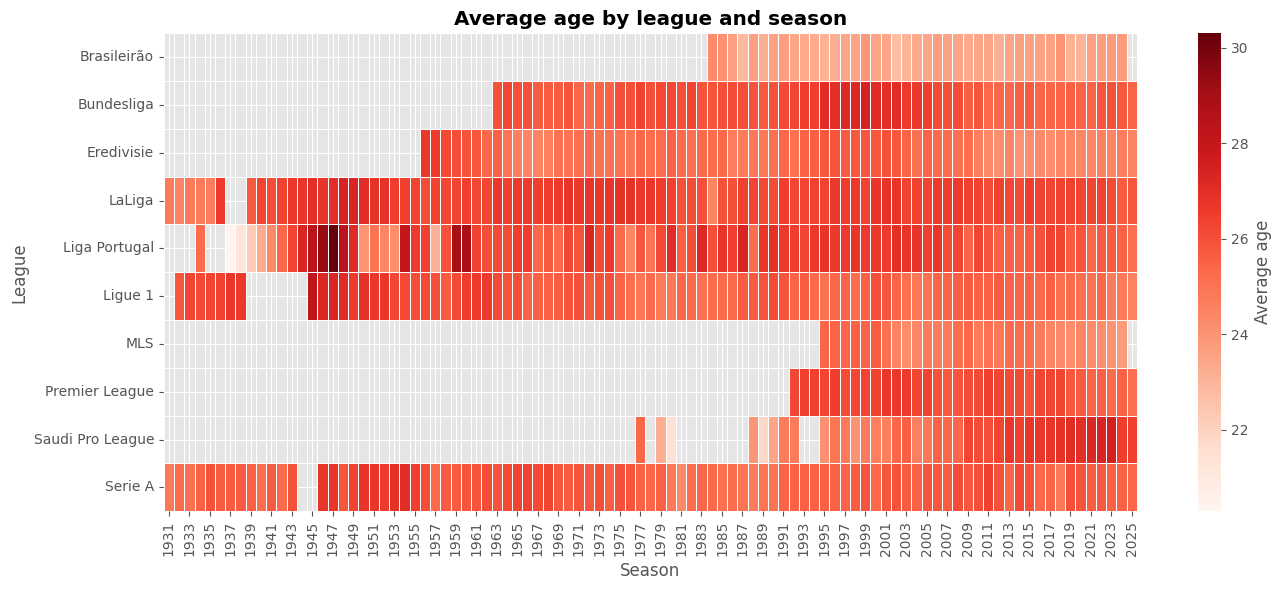

In [17]:
matrix = pd.pivot_table(data=df, index="league", columns="season", values="average_age", aggfunc="mean")

plt.figure(figsize=(14, 6))
sns.heatmap(matrix, annot=False, cmap="Reds", linewidths=0.5,
            cbar_kws={"label": "Average age"})
plt.xlabel("Season")
plt.ylabel("League")
plt.title("Average age by league and season", fontweight="bold")
plt.tight_layout()
plt.show()